# Atividade de Machine Learning: Classificação e Regressão

**Aluno:** Israel Nobre
**Disciplina:** Tópicos Especiais

## 1. Introdução

Este notebook resolve dois problemas de *Machine Learning* supervisionado com Python e Scikit-Learn:

| Parte | Problema | Tipo | Dataset | Modelo |
|---|---|---|---|---|
| **Parte 1** | Classificar tumores de mama como **benignos** ou **malignos** a partir de medidas extraídas de exames | Classificação binária | *Breast Cancer Wisconsin* (Scikit-Learn) | Regressão Logística |
| **Parte 2** | Prever o **valor mediano dos imóveis de uma região** a partir de características socioeconômicas e geográficas | Regressão | *California Housing* (Scikit-Learn) | Regressão Linear |

O notebook segue a estrutura pedida: cada seção é dividida em **Parte 1 (Classificação)** e **Parte 2 (Regressão)**. Ao longo do caminho, as decisões de pré-processamento e avaliação são justificadas e os resultados são interpretados com os números obtidos.

### Como reproduzir

O ambiente foi gerenciado com o [uv](https://docs.astral.sh/uv/) (as versões exatas estão no `uv.lock`):

```bash
uv sync
uv run jupyter lab
```

Alternativamente, com `pip`:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn
```

> **Observação:** o dataset *California Housing* é baixado da internet na primeira execução e depois fica em cache local. Todos os sorteios usam semente fixa (`42`), então reexecutar o notebook produz exatamente os mesmos números.

## 2. Importação das bibliotecas

- **pandas / numpy**: manipulação dos dados em tabelas e cálculos numéricos;
- **matplotlib / seaborn**: gráficos;
- **scikit-learn**: datasets, divisão treino/teste, padronização, modelos e métricas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_absolute_error, mean_squared_error, r2_score,
)

# Semente única usada em todos os sorteios -> resultados reprodutíveis
SEMENTE = 42

# Parte 1: ordem e cores dos diagnósticos nos gráficos
ORDEM_DIAGNOSTICO = ["Benigno", "Maligno"]
CORES_DIAGNOSTICO = {"Benigno": "tab:green", "Maligno": "tab:red"}

# Parte 2: teto do dataset California Housing (valores acima de US$ 500 mil foram gravados como 5,0)
TETO_VALOR = 5.0

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 40)

## 3. Carregamento dos dados

### 3.1 Parte 1: Breast Cancer Wisconsin

O dataset é carregado direto do Scikit-Learn. Com `as_frame=True`, os dados já vêm como `DataFrame` do pandas, com os nomes das colunas.

In [2]:
cancer = load_breast_cancer(as_frame=True)

df_cancer = cancer.frame.copy()
df_cancer.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.990,10.380,122.800,1001.000,0.118,0.278,0.300,0.147,0.242,0.079,1.095,0.905,8.589,153.400,0.006,0.049,0.054,0.016,0.030,0.006,25.380,17.330,184.600,2019.000,0.162,0.666,0.712,0.265,0.460,0.119,0
1,20.570,17.770,132.900,1326.000,0.085,0.079,0.087,0.070,0.181,0.057,0.543,0.734,3.398,74.080,0.005,0.013,0.019,0.013,0.014,0.004,24.990,23.410,158.800,1956.000,0.124,0.187,0.242,0.186,0.275,0.089,0
2,19.690,21.250,130.000,1203.000,0.110,0.160,0.197,0.128,0.207,0.060,0.746,0.787,4.585,94.030,0.006,0.040,0.038,0.021,0.022,0.005,23.570,25.530,152.500,1709.000,0.144,0.424,0.450,0.243,0.361,0.088,0
3,11.420,20.380,77.580,386.100,0.142,0.284,0.241,0.105,0.260,0.097,0.496,1.156,3.445,27.230,0.009,0.075,0.057,0.019,0.060,0.009,14.910,26.500,98.870,567.700,0.210,0.866,0.687,0.258,0.664,0.173,0
4,20.290,14.340,135.100,1297.000,0.100,0.133,0.198,0.104,0.181,0.059,0.757,0.781,5.438,94.440,0.011,0.025,0.057,0.019,0.018,0.005,22.540,16.670,152.200,1575.000,0.137,0.205,0.400,0.163,0.236,0.077,0


Atenção à codificação original do alvo (`target`) no Scikit-Learn:

In [3]:
# Mapeamento original: número da classe -> nome
dict(enumerate(cancer.target_names))

{0: np.str_('malignant'), 1: np.str_('benign')}

No dataset original, **0 = maligno** e **1 = benigno**. Como o Scikit-Learn calcula *precision*, *recall* e *F1* considerando a classe **1** como "positiva", manter essa codificação faria as métricas medirem a detecção de tumores **benignos**. Na seção 5 o alvo será **recodificado** para que a classe positiva seja o **tumor maligno**, que é o que o modelo precisa detectar.

### 3.2 Parte 2: California Housing

Dados do censo de 1990 da Califórnia. **Cada registro é uma região** (*block group*, um agrupamento de quarteirões com algumas centenas a poucos milhares de habitantes), não uma casa individual.

In [4]:
housing = fetch_california_housing(as_frame=True)

df_regioes = housing.frame.copy()
df_regioes.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,2401.000,2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


## 4. Análise exploratória

### 4.1 Parte 1: Breast Cancer Wisconsin

#### Quantidade de registros, atributos e valores ausentes

In [5]:
n_registros, n_colunas = df_cancer.shape
print(f"Quantidade de registros: {n_registros}")
print(f"Quantidade de atributos: {n_colunas - 1}  (+ 1 coluna alvo)")
print(f"Valores ausentes: {df_cancer.isna().sum().sum()}")

Quantidade de registros: 569
Quantidade de atributos: 30  (+ 1 coluna alvo)
Valores ausentes: 0


#### Significado dos atributos

Os 30 atributos descrevem os **núcleos celulares** vistos na imagem digitalizada de uma punção aspirativa (PAAF) do nódulo. São **10 medidas**, cada uma resumida de **3 formas**:

| Prefixo/sufixo | Significado |
|---|---|
| `mean ...` | média da medida entre os núcleos da imagem |
| `... error` | erro padrão da medida |
| `worst ...` | média dos 3 piores (maiores) valores |

| Medida | Significado |
|---|---|
| `radius` | raio (distância do centro ao contorno) |
| `texture` | textura (desvio padrão dos tons de cinza) |
| `perimeter` | perímetro do núcleo |
| `area` | área do núcleo |
| `smoothness` | suavidade (variação local do raio) |
| `compactness` | compacidade (perímetro² / área − 1) |
| `concavity` | concavidade (profundidade das reentrâncias do contorno) |
| `concave points` | número de pontos côncavos do contorno |
| `symmetry` | simetria |
| `fractal dimension` | dimensão fractal (irregularidade do contorno) |

#### Estatísticas descritivas

O `describe()` resume cada atributo (média, desvio padrão, mínimo, quartis e máximo). Serve para verificar a escala de cada um e se há valores fora do esperado.

In [6]:
# .T (transposta) deixa um atributo por linha, mais fácil de ler com 30 atributos
df_cancer.drop(columns="target").describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.000,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.000,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.000,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.000,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.000,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.000,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.000,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.000,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.000,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.000,0.063,0.007,0.050,0.058,0.062,0.066,0.097


As escalas dos atributos são muito diferentes: `mean area` passa de 2.000, enquanto `mean smoothness` fica perto de 0,1. Isso justifica a **padronização** antes da Regressão Logística (seção 5).

#### Distribuição das classes

A proporção entre tumores benignos e malignos é contada e plotada para saber se a base é balanceada. Isso define a referência mínima de accuracy e a necessidade de estratificar a divisão treino/teste.

,quantidade,proporção (%)
target,,
Benigno,357,62.742
Maligno,212,37.258


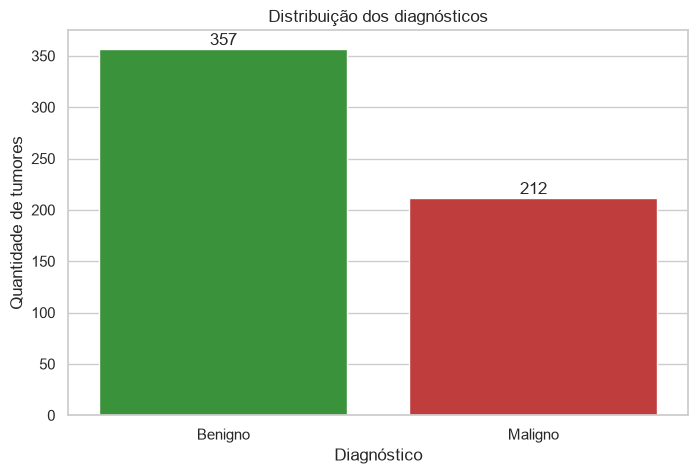

In [7]:
# Rótulos legíveis apenas para a análise exploratória
diagnostico = cancer.target.map({0: "Maligno", 1: "Benigno"})

distribuicao = pd.DataFrame({
    "quantidade": diagnostico.value_counts(),
    "proporção (%)": diagnostico.value_counts(normalize=True) * 100,
})
display(distribuicao)

ax = sns.countplot(x=diagnostico, order=ORDEM_DIAGNOSTICO, hue=diagnostico, palette=CORES_DIAGNOSTICO)
ax.bar_label(ax.containers[0]); ax.bar_label(ax.containers[1])
ax.set_title("Distribuição dos diagnósticos")
ax.set_xlabel("Diagnóstico"); ax.set_ylabel("Quantidade de tumores")
plt.show()

**Interpretação:** a base tem **357 tumores benignos (62,7%)** e **212 malignos (37,3%)**. O desbalanceamento é moderado e tem duas consequências:
- um modelo "preguiçoso", que respondesse sempre "benigno", já acertaria cerca de **63%**. A accuracy do modelo precisa ser comparada com essa referência, e não com 50%;
- a accuracy sozinha pode esconder um desempenho ruim justamente na classe minoritária (maligno), que é a mais importante. Por isso a avaliação vai olhar com atenção para **recall** e **precision** da classe maligna, e a divisão treino/teste será **estratificada**.

#### Atributos que separam as classes

Três atributos (tamanho, irregularidade do contorno e textura) comparados entre tumores benignos e malignos. Se as distribuições quase não se sobrepõem, o atributo ajuda muito a separar as classes. Os títulos usam os nomes originais das colunas, traduzidos na tabela acima.

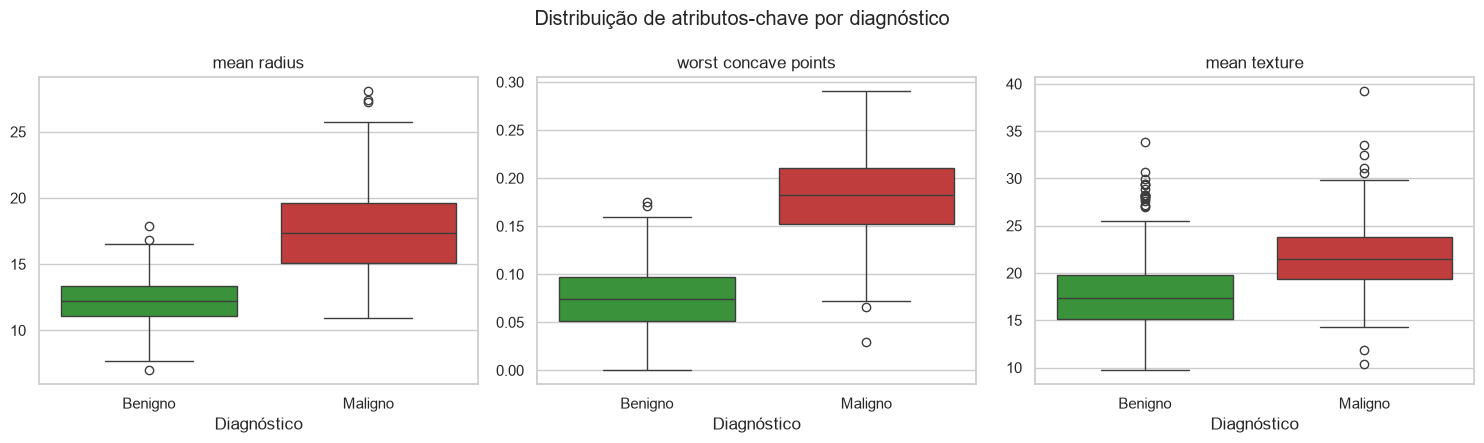

,mean radius,worst concave points,mean texture
target,,,
Benigno,12.200,0.074,17.390
Maligno,17.325,0.182,21.460


In [8]:
atributos_chave = ["mean radius", "worst concave points", "mean texture"]

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.5))
for eixo, atributo in zip(eixos, atributos_chave):
    sns.boxplot(x=diagnostico, y=df_cancer[atributo], order=ORDEM_DIAGNOSTICO,
                hue=diagnostico, palette=CORES_DIAGNOSTICO, ax=eixo)
    eixo.set_title(atributo); eixo.set_xlabel("Diagnóstico"); eixo.set_ylabel("")
fig.suptitle("Distribuição de atributos-chave por diagnóstico")
plt.tight_layout()
plt.show()

# Medianas por diagnóstico (valores citados na interpretação)
df_cancer[atributos_chave].groupby(diagnostico).median().loc[ORDEM_DIAGNOSTICO]

**Interpretação:** os tumores malignos têm núcleos **maiores** (mediana de `mean radius` de 17,3 contra 12,2 nos benignos) e com **contorno mais irregular** (mediana de `worst concave points` de 0,182 contra 0,074). Nesses dois atributos as caixas quase não se sobrepõem, ou seja, sozinhos eles já separam bem as classes. Já `mean texture` mostra diferença (21,5 contra 17,4), mas com bastante sobreposição.

Isso indica que as classes são **quase linearmente separáveis**, o que justifica esperar um bom desempenho de um modelo linear como a Regressão Logística.

### 4.2 Parte 2: California Housing

#### Quantidade de registros, atributos e valores ausentes

In [9]:
n_registros, n_colunas = df_regioes.shape
print(f"Quantidade de registros (regiões): {n_registros}")
print(f"Quantidade de atributos: {n_colunas - 1}  (+ 1 coluna alvo)")
print(f"Valores ausentes: {df_regioes.isna().sum().sum()}")

Quantidade de registros (regiões): 20640
Quantidade de atributos: 8  (+ 1 coluna alvo)
Valores ausentes: 0


#### Significado das variáveis

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana das famílias da região (em dezenas de milhares de US$) |
| `HouseAge` | idade mediana das casas da região (anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos por domicílio |
| `Population` | população da região |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude do centro da região |
| `Longitude` | longitude do centro da região |
| **`MedHouseVal`** | **alvo**: valor mediano dos imóveis da região, em **centenas de milhares de US$** (ex.: 2,5 = US$ 250.000) |

#### Estatísticas descritivas

Resumo de cada variável, para verificar escalas, valores extremos e o intervalo do alvo.

In [10]:
df_regioes.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.000,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.000,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.000,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.000,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.000,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.000,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.000,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.000,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.000,2.069,1.154,0.150,1.196,1.797,2.647,5.000


Algumas variáveis têm valores extremos: `AveOccup` e `AveRooms` chegam a centenas ou milhares, em geral regiões com poucos domicílios ou com hotéis e alojamentos. O máximo de `MedHouseVal` é exatamente **5,0**, o que é suspeito e será investigado a seguir.

#### Distribuição da variável alvo

O histograma mostra como o valor mediano se distribui entre as regiões e permite investigar o máximo suspeito de 5,0. Também são contados os valores que mais se repetem.

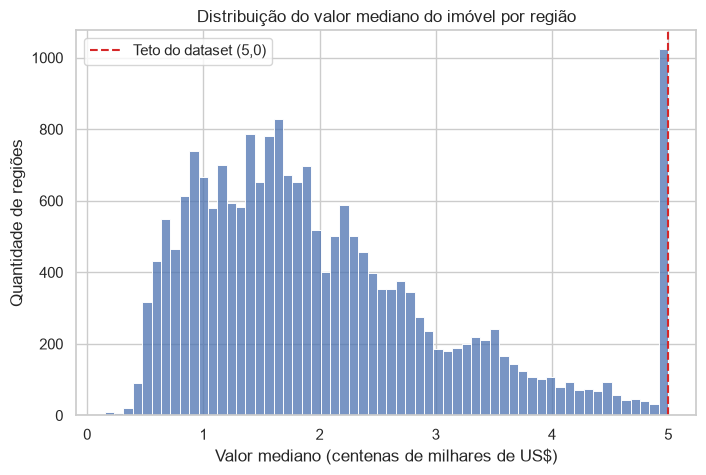

Regiões com valor no teto (>= 5,0): 992 (4.8%)

Valores do alvo que mais se repetem:
MedHouseVal
5.000    965
1.375    122
1.625    117
1.125    103
1.875     93


In [11]:
truncados = (df_regioes["MedHouseVal"] >= TETO_VALOR).sum()

ax = sns.histplot(df_regioes["MedHouseVal"], bins=60)
ax.axvline(TETO_VALOR, color="tab:red", linestyle="--", label="Teto do dataset (5,0)")
ax.set_title("Distribuição do valor mediano do imóvel por região")
ax.set_xlabel("Valor mediano (centenas de milhares de US$)")
ax.set_ylabel("Quantidade de regiões")
ax.legend()
plt.show()

print(f"Regiões com valor no teto (>= 5,0): {truncados} ({truncados / len(df_regioes):.1%})")
print("\nValores do alvo que mais se repetem:")
print(df_regioes["MedHouseVal"].value_counts().head(5).to_string())

**Interpretação:** a distribuição é assimétrica à direita: metade das regiões tem valor mediano entre US$ 120 mil e US$ 265 mil (mediana de 1,80, ou US$ 180 mil). O pico isolado em **5,0** é artificial: **992 regiões (4,8%)** estão no teto do dataset, sendo **965** com o valor 5,00001 (exibido como `5.000` na contagem acima por causa do arredondamento em 3 casas), o mais frequente de toda a base, e as demais com exatamente 5,0. Na prática, qualquer região com valor mediano acima de US$ 500 mil aparece como US$ 500 mil (**valor truncado**).

Para esses registros o valor real é desconhecido (sabe-se apenas que é ≥ 5,0). Isso vai prejudicar a regressão linear: o modelo tende a prever valores acima de 5,0 para regiões ricas, que serão contabilizados como erro mesmo quando estiverem mais perto do valor verdadeiro.

#### Correlação entre as variáveis

A correlação de Pearson mede a força da relação **linear** entre pares de variáveis (de −1 a 1). Ela indica quais variáveis devem pesar mais na Regressão Linear e quais são redundantes entre si.

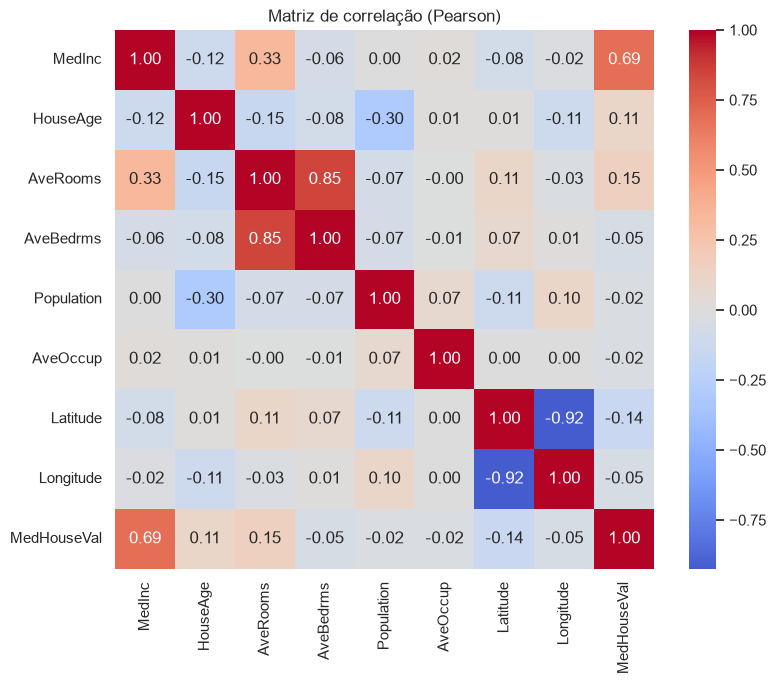

Correlação de cada variável com o valor mediano:
MedInc        0.688
AveRooms      0.152
Latitude     -0.144
HouseAge      0.106
AveBedrms    -0.047
Longitude    -0.046
Population   -0.025
AveOccup     -0.024

AveRooms × AveBedrms: 0.848
Latitude × Longitude: -0.925


In [12]:
correlacoes = df_regioes.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Matriz de correlação (Pearson)")
plt.show()

print("Correlação de cada variável com o valor mediano:")
print(correlacoes["MedHouseVal"].drop("MedHouseVal").sort_values(key=abs, ascending=False).round(3).to_string())
print(f"\nAveRooms × AveBedrms: {correlacoes.loc['AveRooms', 'AveBedrms']:.3f}")
print(f"Latitude × Longitude: {correlacoes.loc['Latitude', 'Longitude']:.3f}")

**Interpretação:** a **renda mediana (`MedInc`) é de longe a variável mais correlacionada com o valor dos imóveis (0,69)**. Todas as demais têm correlação linear fraca com o alvo (em módulo, abaixo de 0,16).

Dois outros pontos aparecem na matriz:
- `AveRooms` e `AveBedrms` são fortemente correlacionadas entre si (0,85), assim como `Latitude` e `Longitude` (−0,92). Essa **multicolinearidade** não atrapalha as previsões, mas torna os coeficientes individuais dessas variáveis menos confiáveis para interpretação;
- correlação baixa não significa que a variável é inútil. Latitude e longitude, por exemplo, têm correlação fraca com o valor quando vistas isoladamente, mas **combinadas** indicam a proximidade do litoral e de cidades como São Francisco e Los Angeles, como os coeficientes do modelo vão mostrar.

#### Renda mediana × valor mediano do imóvel

Gráfico de dispersão da variável mais correlacionada com o alvo, para ver a forma da relação (se é linear e se a dispersão é constante).

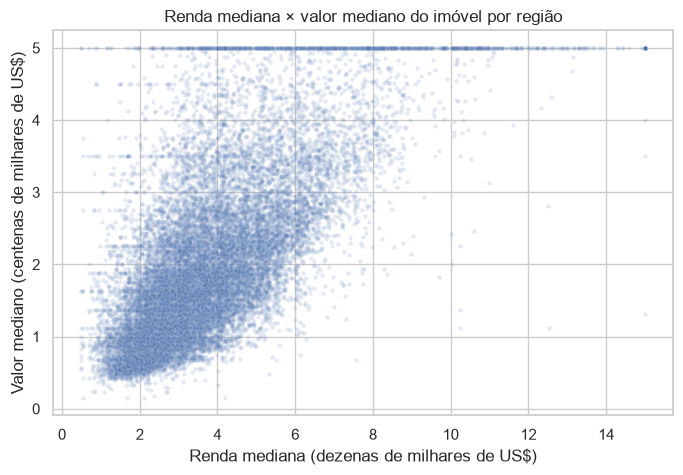

In [13]:
ax = sns.scatterplot(data=df_regioes, x="MedInc", y="MedHouseVal", alpha=0.15, s=10)
ax.set_title("Renda mediana × valor mediano do imóvel por região")
ax.set_xlabel("Renda mediana (dezenas de milhares de US$)")
ax.set_ylabel("Valor mediano (centenas de milhares de US$)")
plt.show()

**Interpretação:** há uma tendência clara de **quanto maior a renda da região, maior o valor dos imóveis**, aproximadamente linear. Porém a dispersão aumenta com a renda (o "funil" se abre para a direita), e aparece a **linha horizontal em 5,0** formada pelas regiões truncadas. Além disso, alguns valores do alvo se repetem muito mais que o esperado (1,375 e 1,625, por exemplo, aparecem 122 e 117 vezes, como mostra a contagem na seção anterior), outro indício de arredondamento na coleta dos dados.

## 5. Pré-processamento

### 5.1 Parte 1: Breast Cancer Wisconsin

**Separação entre X e y e recodificação do alvo.** As variáveis independentes (`X`) são os 30 atributos dos núcleos celulares. A variável alvo (`y`) é recodificada para **1 = tumor maligno (classe positiva)** e **0 = tumor benigno**, seguindo a convenção de exames médicos, em que "positivo" significa que a doença foi detectada.

In [14]:
X_cancer = cancer.data
y_cancer = (cancer.target == 0).astype(int)  # 1 = maligno, 0 = benigno

print("Formato de X:", X_cancer.shape)
print("Contagem de y:", y_cancer.value_counts().rename({0: "Benigno (0)", 1: "Maligno (1)"}).to_dict())

Formato de X: (569, 30)
Contagem de y: {'Benigno (0)': 357, 'Maligno (1)': 212}


**Divisão treino/teste (80% / 20%).** O parâmetro `stratify=y` mantém nos dois conjuntos a mesma proporção de tumores malignos e benignos. Isso é importante numa base pequena (569 registros) e desbalanceada, em que um sorteio sem estratificação poderia deixar o teste com proporção diferente e distorcer as métricas.

In [15]:
X_treino_clf, X_teste_clf, y_treino_clf, y_teste_clf = train_test_split(
    X_cancer, y_cancer, test_size=0.2, stratify=y_cancer, random_state=SEMENTE
)

print(f"Treino: {len(X_treino_clf)} registros | Teste: {len(X_teste_clf)} registros")
print(f"Proporção de malignos -> treino: {y_treino_clf.mean():.1%} | teste: {y_teste_clf.mean():.1%}")

Treino: 455 registros | Teste: 114 registros


Proporção de malignos -> treino: 37.4% | teste: 36.8%


**Padronização.** O `StandardScaler` transforma cada atributo para média 0 e desvio padrão 1. Sem isso, atributos de escala grande (como `area`) dominariam a otimização da Regressão Logística e os coeficientes não seriam comparáveis.

O *scaler* é colocado dentro de um `Pipeline` junto com o modelo. Assim, a média e o desvio padrão são calculados **apenas com os dados de treino** e depois aplicados ao teste. Isso evita *data leakage*, isto é, que informação do conjunto de teste vaze para o treinamento.

### 5.2 Parte 2: California Housing

**Variável dependente e independentes.**
- **Dependente (y):** `MedHouseVal`, o valor mediano do imóvel por região;
- **Independentes (X):** as 8 demais variáveis.

As regiões com valor no teto de 5,0 são **mantidas**. Removê-las melhoraria artificialmente as métricas, mas o modelo deixaria de representar os dados reais. O efeito desses registros é discutido na avaliação.

In [16]:
X_regioes = df_regioes.drop(columns="MedHouseVal")
y_regioes = df_regioes["MedHouseVal"]

X_treino_reg, X_teste_reg, y_treino_reg, y_teste_reg = train_test_split(
    X_regioes, y_regioes, test_size=0.2, random_state=SEMENTE
)

print("Variáveis independentes:", list(X_regioes.columns))
print(f"Treino: {len(X_treino_reg)} regiões | Teste: {len(X_teste_reg)} regiões")

Variáveis independentes: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Treino: 16512 regiões | Teste: 4128 regiões


**Padronização.** Para a Regressão Linear, a padronização **não altera as previsões** (MAE, RMSE e R² são os mesmos com ou sem ela). Ela é aplicada para que os **coeficientes fiquem comparáveis entre si**: cada coeficiente passa a indicar quanto o valor previsto muda quando a variável aumenta **1 desvio padrão**. Assim como na Parte 1, o *scaler* fica num `Pipeline` e é ajustado só no treino.

## 6. Treinamento dos modelos

### 6.1 Parte 1: Regressão Logística

A **Regressão Logística** estima a probabilidade de um tumor ser maligno combinando linearmente os atributos e aplicando a função sigmoide. Se a probabilidade for maior ou igual a 50%, o tumor é classificado como maligno. Foi escolhida por ser simples, rápida e interpretável: os coeficientes mostram quais atributos puxam a decisão para "maligno".

In [17]:
modelo_classificacao = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEMENTE)),
])

modelo_classificacao.fit(X_treino_clf, y_treino_clf)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('padronizacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### 6.2 Parte 2: Regressão Linear

A **Regressão Linear** ajusta uma combinação linear das variáveis (`valor ≈ b₀ + b₁·x₁ + … + b₈·x₈`) que minimiza a soma dos erros ao quadrado no treino.

In [18]:
modelo_regressao = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LinearRegression()),
])

modelo_regressao.fit(X_treino_reg, y_treino_reg)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('padronizacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 7. Avaliação dos resultados

Todas as métricas são calculadas no **conjunto de teste**, com dados que o modelo nunca viu no treinamento.

### 7.1 Parte 1: Classificação

#### Accuracy, Precision, Recall e F1-Score

Lembrando que a **classe positiva é o tumor maligno**:
- **Accuracy**: proporção de acertos no total;
- **Precision**: dos tumores que o modelo apontou como malignos, quantos realmente eram;
- **Recall**: dos tumores realmente malignos, quantos o modelo detectou;
- **F1-Score**: média harmônica entre precision e recall.

In [19]:
y_previsto_clf = modelo_classificacao.predict(X_teste_clf)

metricas_classificacao = pd.Series({
    "Accuracy": accuracy_score(y_teste_clf, y_previsto_clf),
    "Precision (maligno)": precision_score(y_teste_clf, y_previsto_clf),
    "Recall (maligno)": recall_score(y_teste_clf, y_previsto_clf),
    "F1-Score (maligno)": f1_score(y_teste_clf, y_previsto_clf),
}, name="valor")
metricas_classificacao.to_frame()

,valor
Accuracy,0.965
Precision (maligno),0.975
Recall (maligno),0.929
F1-Score (maligno),0.951


#### Matriz de Confusão

A matriz cruza o diagnóstico real com o previsto e mostra **que tipo de erro** o modelo comete, algo que a accuracy esconde. O erro que mais importa aqui é o **falso negativo** (tumor maligno classificado como benigno).

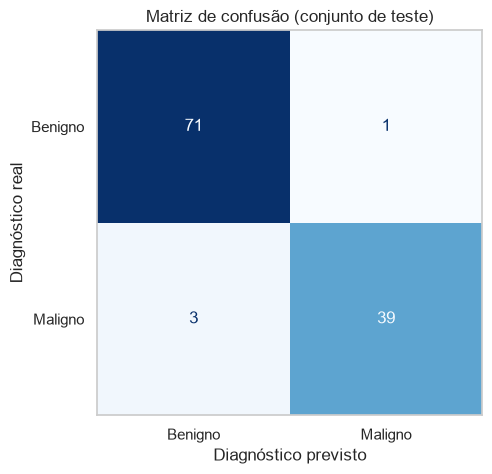

Verdadeiros negativos (benigno corretamente identificado): 71
Falsos positivos (benigno classificado como maligno):      1
Falsos negativos (maligno classificado como benigno):      3
Verdadeiros positivos (maligno corretamente detectado):    39


In [20]:
matriz = confusion_matrix(y_teste_clf, y_previsto_clf)
vn, fp, fn, vp = matriz.ravel()  # ordem do sklearn: [[VN, FP], [FN, VP]]

ConfusionMatrixDisplay(matriz, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusão (conjunto de teste)")
plt.xlabel("Diagnóstico previsto"); plt.ylabel("Diagnóstico real")
plt.grid(False)
plt.show()

print(f"Verdadeiros negativos (benigno corretamente identificado): {vn}")
print(f"Falsos positivos (benigno classificado como maligno):      {fp}")
print(f"Falsos negativos (maligno classificado como benigno):      {fn}")
print(f"Verdadeiros positivos (maligno corretamente detectado):    {vp}")

#### Relatório completo por classe

O `classification_report` mostra precision, recall e F1 **das duas classes**, o que permite comparar o desempenho do modelo em tumores benignos e malignos.

In [21]:
print(classification_report(y_teste_clf, y_previsto_clf, target_names=["Benigno", "Maligno"], digits=3))

              precision    recall  f1-score   support

     Benigno      0.959     0.986     0.973        72
     Maligno      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



#### Atributos que mais pesam na decisão

Como os atributos foram padronizados, os coeficientes da Regressão Logística podem ser comparados entre si. Coeficiente **positivo** aumenta a chance de o tumor ser classificado como **maligno**; coeficiente **negativo** diminui.

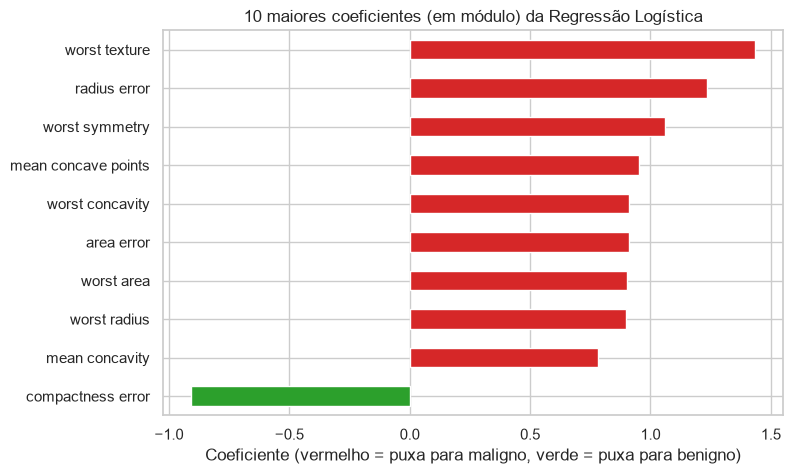

In [22]:
coeficientes_clf = pd.Series(
    modelo_classificacao.named_steps["modelo"].coef_[0], index=X_cancer.columns
)
top10 = coeficientes_clf.sort_values(key=abs, ascending=False).head(10).sort_values()

cores = ["tab:red" if c > 0 else "tab:green" for c in top10]
ax = top10.plot.barh(color=cores, figsize=(8, 5))
ax.set_title("10 maiores coeficientes (em módulo) da Regressão Logística")
ax.set_xlabel("Coeficiente (vermelho = puxa para maligno, verde = puxa para benigno)")
plt.show()

#### Análise dos resultados da classificação

No conjunto de teste (114 tumores: 72 benignos e 42 malignos), a Regressão Logística obteve:

| Métrica | Valor | Leitura |
|---|---|---|
| **Accuracy** | **96,5%** | acertou 110 de 114 tumores, bem acima da referência de ~63% de responder sempre "benigno" |
| **Precision (maligno)** | **97,5%** | dos 40 tumores apontados como malignos, 39 realmente eram |
| **Recall (maligno)** | **92,9%** | dos 42 tumores malignos, o modelo detectou 39 |
| **F1-Score (maligno)** | **95,1%** | bom equilíbrio entre precision e recall |

**O erro que mais importa.** A matriz de confusão mostra só 4 erros, mas eles não têm o mesmo peso:
- **1 falso positivo:** um tumor benigno foi classificado como maligno. A consequência é um susto e exames adicionais (como uma biópsia), que confirmariam que o tumor é benigno;
- **3 falsos negativos:** três tumores **malignos foram classificados como benignos**. Num cenário real, são três pacientes com câncer que poderiam ser mandados para casa sem tratamento.

Por isso, mesmo com accuracy de 96,5%, a métrica mais relevante aqui é o **recall da classe maligna (92,9%)**: cerca de **1 em cada 14 cânceres não seria detectado**. O modelo erra mais "para o lado perigoso" (3 FN contra 1 FP). Isso aparece também no relatório por classe: o recall do benigno é 98,6%, enquanto o do maligno é 92,9%.

Como o modelo fornece **probabilidades**, uma forma de priorizar o recall seria **reduzir o limiar de decisão** (por exemplo, classificar como maligno a partir de 30% de probabilidade, e não de 50%). Isso troca alguns falsos negativos por falsos positivos, que são muito menos graves neste contexto.

**Atributos mais importantes.** Os maiores coeficientes positivos (que puxam para "maligno") são `worst texture`, `radius error`, `worst symmetry` e medidas de concavidade e tamanho (`mean concave points`, `worst concavity`, `area error`, `worst area`, `worst radius`, `mean concavity`). Isso é coerente com a análise exploratória: tumores malignos têm núcleos maiores, mais irregulares e mais heterogêneos. Esses coeficientes devem ser lidos com cautela, porém: atributos como raio, perímetro e área são quase redundantes entre si (multicolinearidade), então o modelo "divide" o peso entre eles de forma um tanto arbitrária. Isso explica, por exemplo, `compactness error` aparecer com sinal negativo.

**Ressalva:** o teste tem apenas 114 tumores (42 malignos). Cada falso negativo a mais ou a menos muda o recall em cerca de 2,4 pontos percentuais, então esses números têm uma margem de incerteza considerável.

### 7.2 Parte 2: Regressão

#### MAE, MSE, RMSE e R²

- **MAE** (erro absoluto médio): o quanto, em média, a previsão erra para mais ou para menos;
- **MSE** (erro quadrático médio): média dos erros ao quadrado, que penaliza mais os erros grandes;
- **RMSE** (raiz do MSE): volta à unidade do alvo, o que facilita a interpretação;
- **R²**: proporção da variação do valor dos imóveis que o modelo consegue explicar (1 = perfeito, 0 = equivale a sempre prever a média).

In [23]:
y_previsto_reg = modelo_regressao.predict(X_teste_reg)

mae = mean_absolute_error(y_teste_reg, y_previsto_reg)
mse = mean_squared_error(y_teste_reg, y_previsto_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_teste_reg, y_previsto_reg)

def em_dolares(valor):
    """Converte da unidade do alvo (centenas de milhares de US$) para US$, no formato brasileiro."""
    return f"US$ {valor * 100_000:,.0f}".replace(",", ".")

metricas_regressao = pd.DataFrame({
    "valor (centenas de milhares de US$)": [mae, mse, rmse, r2],
    "valor em US$": [em_dolares(mae), "-", em_dolares(rmse), "-"],
}, index=["MAE", "MSE", "RMSE", "R²"])
metricas_regressao

,valor (centenas de milhares de US$),valor em US$
MAE,0.533,US$ 53.320
MSE,0.556,-
RMSE,0.746,US$ 74.558
R²,0.576,-


#### Valores reais × previstos

Cada ponto é uma região do teste. Quanto mais perto da diagonal vermelha (previsão perfeita), melhor a previsão. Pontos acima da diagonal são superestimados e pontos abaixo, subestimados.

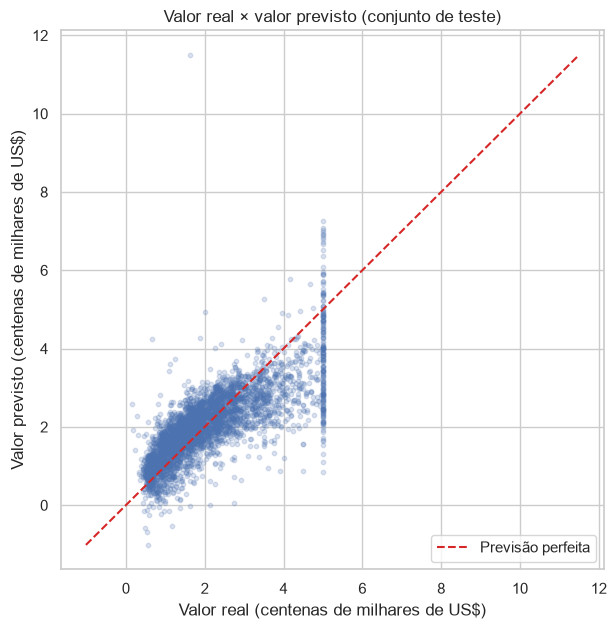

In [24]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_teste_reg, y_previsto_reg, alpha=0.2, s=10)
limites = [min(y_teste_reg.min(), y_previsto_reg.min()), max(y_teste_reg.max(), y_previsto_reg.max())]
ax.plot(limites, limites, color="tab:red", linestyle="--", label="Previsão perfeita")
ax.set_title("Valor real × valor previsto (conjunto de teste)")
ax.set_xlabel("Valor real (centenas de milhares de US$)")
ax.set_ylabel("Valor previsto (centenas de milhares de US$)")
ax.legend()
plt.show()

#### Análise dos resíduos

O resíduo é a diferença `valor real − valor previsto`. Em um bom modelo linear, os resíduos ficam espalhados aleatoriamente em torno de zero, sem formar padrões.

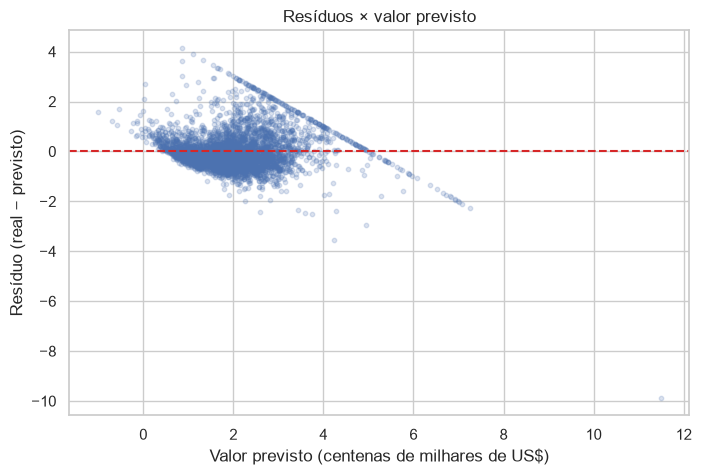

Resíduo médio nas regiões no teto (5,0):  1.153  (184 regiões)
Resíduo médio nas demais regiões:         -0.050
Previsões para as regiões no teto: de 0.85 a 7.26


In [25]:
residuos = y_teste_reg - y_previsto_reg

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_previsto_reg, residuos, alpha=0.2, s=10)
ax.axhline(0, color="tab:red", linestyle="--")
ax.set_title("Resíduos × valor previsto")
ax.set_xlabel("Valor previsto (centenas de milhares de US$)")
ax.set_ylabel("Resíduo (real − previsto)")
plt.show()

no_teto = y_teste_reg >= TETO_VALOR
print(f"Resíduo médio nas regiões no teto (5,0):  {residuos[no_teto].mean():.3f}  ({no_teto.sum()} regiões)")
print(f"Resíduo médio nas demais regiões:         {residuos[~no_teto].mean():.3f}")
print(f"Previsões para as regiões no teto: de {y_previsto_reg[no_teto].min():.2f} a {y_previsto_reg[no_teto].max():.2f}")

#### Previsões extremas

As regiões com previsões impossíveis (valor negativo) e a região com a maior previsão são investigadas abaixo, para entender onde o modelo linear extrapola.

In [26]:
negativas = y_previsto_reg < 0
print(f"Previsões negativas (valor impossível): {negativas.sum()}")
print(f"Renda mediana dessas regiões: {X_teste_reg.loc[negativas, 'MedInc'].median():.2f} (dezenas de milhares de US$)")

i_max = y_previsto_reg.argmax()
print(f"\nMaior previsão: {y_previsto_reg[i_max]:.2f} (valor real: {y_teste_reg.iloc[i_max]:.2f})")
X_teste_reg.iloc[i_max].to_frame("região com a maior previsão")

Previsões negativas (valor impossível): 15
Renda mediana dessas regiões: 1.74 (dezenas de milhares de US$)

Maior previsão: 11.50 (valor real: 1.62)


,região com a maior previsão
MedInc,4.625
HouseAge,34.000
AveRooms,132.533
AveBedrms,34.067
Population,36.000
AveOccup,2.400
Latitude,38.800
Longitude,-120.080


#### Coeficientes padronizados

Cada barra indica quanto o valor mediano previsto muda (em centenas de milhares de US$) quando a variável aumenta **1 desvio padrão**, mantendo as demais constantes.

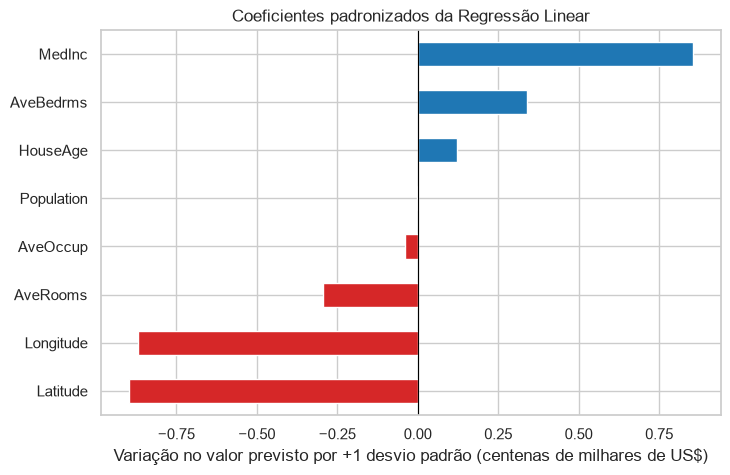

,coeficiente
Latitude,-0.897
Longitude,-0.870
MedInc,0.854
AveBedrms,0.339
AveRooms,-0.294
HouseAge,0.123
AveOccup,-0.041
Population,-0.002


In [27]:
coeficientes_reg = pd.Series(
    modelo_regressao.named_steps["modelo"].coef_, index=X_regioes.columns
).sort_values()

ax = coeficientes_reg.plot.barh(color=["tab:red" if c < 0 else "tab:blue" for c in coeficientes_reg])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coeficientes padronizados da Regressão Linear")
ax.set_xlabel("Variação no valor previsto por +1 desvio padrão (centenas de milhares de US$)")
plt.show()

coeficientes_reg.sort_values(key=abs, ascending=False).to_frame("coeficiente")

#### Interpretação dos resultados da regressão

| Métrica | Valor | Leitura |
|---|---|---|
| **MAE** | **0,533** (≈ US$ 53 mil) | em média, a previsão erra o valor mediano da região em cerca de US$ 53 mil, para mais ou para menos |
| **MSE** | **0,556** | difícil de interpretar diretamente (unidade ao quadrado); serve de base para o RMSE |
| **RMSE** | **0,746** (≈ US$ 75 mil) | maior que o MAE porque alguns erros são grandes; o RMSE os penaliza mais |
| **R²** | **0,576** | o modelo explica cerca de **58% da variação** do valor dos imóveis entre as regiões |

**O resultado é razoável, mas limitado.** Considerando que o valor mediano típico é de US$ 180 mil, um erro médio de US$ 53 mil é **grande** (cerca de 30%). O R² de 0,58 mostra que o modelo capta a tendência geral, mas **42% da variação fica sem explicação**.

**O que os gráficos revelam:**
1. **Efeito do valor truncado:** no gráfico real × previsto, a coluna vertical em 5,0 mostra regiões cujo valor real foi truncado. Para elas, o modelo prevê desde ~1 até mais de 7. Nas **184 regiões truncadas do teste**, o resíduo médio é de **+1,15**, ou seja, o modelo prevê em média US$ 115 mil abaixo do teto, enquanto nas demais regiões o resíduo médio é praticamente zero (−0,05). Parte desse "erro" nem é real, porque o valor verdadeiro dessas regiões é desconhecido e provavelmente maior que 5,0.
2. **Padrão nos resíduos:** os resíduos não estão espalhados aleatoriamente. A faixa diagonal descendente no gráfico de resíduos é formada pelas regiões truncadas (real fixo em 5,0, então o resíduo cai à medida que a previsão sobe), e a nuvem principal é inclinada: o modelo superestima regiões baratas e subestima as caras. Isso indica que **a relação entre as variáveis e o valor não é totalmente linear**.
3. **Previsões impossíveis:** **15 regiões** receberam valor previsto **negativo**. São regiões de baixa renda (renda mediana de cerca de US$ 17 mil) no interior e no norte do estado, onde a soma linear dos efeitos de renda e localização "passa do zero". No outro extremo, uma região teve previsão de **11,5** (mais que o dobro do máximo possível) por causa de valores absurdos de `AveRooms` (132 cômodos por domicílio) e `AveBedrms` (34), provavelmente uma área de casas de veraneio ou um erro de registro. O modelo linear extrapola sem limite para esses casos.

**Coeficientes padronizados:**
- **`MedInc` (+0,85):** cada +1 desvio padrão de renda mediana (≈ US$ 19 mil) aumenta o valor previsto em ≈ US$ 85 mil, confirmando a correlação vista na análise exploratória;
- **`Latitude` (−0,90) e `Longitude` (−0,87):** têm os **maiores** coeficientes, apesar da correlação individual fraca. Os sinais negativos indicam que, mantido o resto constante, quanto mais ao **sul** e mais a **oeste** (em direção ao litoral do Pacífico), maior o valor previsto. Juntas, elas capturam a geografia do estado. Como as duas são fortemente correlacionadas entre si, os coeficientes individuais devem ser lidos em conjunto;
- **`AveBedrms` (+0,34) e `AveRooms` (−0,29):** sinais opostos, efeito da multicolinearidade entre essas duas variáveis. Isoladamente, os sinais não devem ser interpretados como "mais cômodos desvalorizam o imóvel";
- **`Population` e `AveOccup`:** coeficientes próximos de zero, pouco contribuem para o modelo linear.

## 8. Conclusão

### Parte 1: Classificação de tumores

A Regressão Logística teve **ótimo desempenho**: **96,5% de accuracy**, **97,5% de precision** e **92,9% de recall** para tumores malignos, errando apenas 4 de 114 casos no teste. O resultado era esperado, porque a análise exploratória mostrou que atributos como o tamanho e a concavidade dos núcleos já separam as classes quase linearmente.

A análise crítica, porém, mostra que **a accuracy não conta a história toda**. Três dos quatro erros foram **falsos negativos**, isto é, cânceres classificados como benignos, que é o erro mais grave num diagnóstico. Em uso real, o modelo deveria ser ajustado para priorizar o recall (por exemplo, reduzindo o limiar de decisão) e funcionar como **ferramenta de apoio** ao médico, e não como substituto do diagnóstico. Também vale lembrar que a base é pequena (569 casos) e vem de uma única instituição, então o desempenho em outros hospitais e equipamentos não está garantido.

### Parte 2: Previsão do valor mediano do imóvel por região

A Regressão Linear obteve **R² de 0,58**, **MAE de ≈ US$ 53 mil** e **RMSE de ≈ US$ 75 mil**. O modelo capta a tendência principal, em que **renda e localização** são os maiores determinantes do valor, mas o erro é alto em relação ao valor típico (≈ US$ 180 mil) e 42% da variação fica sem explicação.

As principais limitações identificadas foram:
- **Valor truncado em 5,0:** 4,8% das regiões têm valor real desconhecido (acima de US$ 500 mil), o que gera erros sistemáticos nas regiões mais caras;
- **Relações não lineares:** o padrão nos resíduos e as previsões negativas (15 regiões) mostram que uma reta não descreve bem os dados, especialmente nos extremos. A localização, por exemplo, afeta o valor de forma complexa (proximidade do litoral, de grandes cidades), algo que latitude e longitude entram no modelo linear apenas como "quanto mais ao sul/oeste, mais caro";
- **Multicolinearidade** entre algumas variáveis, o que limita a interpretação individual dos coeficientes;
- **Unidade de análise:** o modelo prevê o valor **mediano de uma região** do censo de **1990**, não o preço de uma casa específica nem valores atuais.

Como melhorias, seria possível: tratar ou modelar separadamente as regiões truncadas; criar variáveis derivadas (como distância até o litoral ou até as grandes cidades); aplicar transformações como o logaritmo do valor e da renda; e testar modelos não lineares (como *Random Forest* ou *Gradient Boosting*), que costumam capturar melhor esse tipo de relação.

### Comparação entre os dois problemas

Os dois casos mostram que **um modelo simples pode ser suficiente ou não, dependendo da estrutura dos dados**. No câncer de mama, as classes são quase linearmente separáveis e um modelo linear chega a um desempenho excelente. No mercado imobiliário, as relações são não lineares e os dados têm limitações de coleta (truncamento), então o mesmo tipo de modelo fica limitado. Em ambos, a **análise exploratória foi essencial** para antecipar o comportamento dos modelos, e as métricas só ganharam significado quando interpretadas no **contexto do problema**: o custo de um falso negativo na medicina e o tamanho do erro em dólares no mercado imobiliário.